# 10: Performance metrics

Every final model, scored on its untouched test split, with the full metric set and 95% confidence intervals.

- **Splits.** *Group*: test behaviors never seen in training (the honest generalization estimate). *Random*: stratified random split (comparable to published work).
- **Tasks.** 13 attack types, and 8 attack families.
- **Intervals.** Cluster bootstrap over behavior groups (`src/evaluation/report.py`): flows that look alike differ only in ports, so whole groups are resampled together, which keeps the intervals honest. 1,000 resamples, shared by all models so that differences between two models are paired.
- **Attack vs. benign.** Any attack class counts as attack: detection rate = share of attack flows flagged, false positive rate = share of benign flows flagged.
- Predictions come from `experiments/collect_predictions.py`.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

from src.evaluation.report import (bootstrap_draws, bootstrap_metrics, confusion_by_bucket, interval, per_class_table, summary_metrics)
from src.preprocessing.labels import CLASSES, FAMILY_CLASSES

ROOT = Path("..").resolve()
PRED, REPORTS, FIGS = ROOT / "data/processed/predictions", ROOT / "reports", ROOT / "reports/figures"
NAMES = {"13": list(CLASSES), "family": list(FAMILY_CLASSES)}
DISPLAY = {"xgboost": "XGBoost", "xgboost__no_ports": "XGBoost (no ports)", "logistic_regression": "Logistic regression",
           "cnn_bilstm_attention_v1": "CNN-BiLSTM-Attention v1", "cnn_bilstm_attention_v2": "CNN-BiLSTM-Attention v2",
           "cnn_bilstm_attention_v2___offsets": "CNN-BiLSTM-Attention v2 + offsets", "xgboost___offsets": "XGBoost + offsets",
           "lightgbm": "LightGBM", "paper_cnn_1_epoch": "Paper CNN (1 epoch)", "paper_lstm_1_epoch": "Paper LSTM (1 epoch)",
           "paper_cnn_10_epochs": "Paper CNN (10 epochs)"}
draws = bootstrap_draws(repeats=1000, seed=0)
files = sorted(PRED.glob("*.npz"))
print(len(files), "prediction files")

18 prediction files


## Metrics with confidence intervals

In [2]:
rows, per_class_rows, boot, curves = [], [], {}, {}
for f in files:
    task, split, raw = f.stem.split("_", 2)
    slug = DISPLAY.get(raw, raw)
    d = np.load(f)
    n_classes = len(NAMES[task])
    cm_b = confusion_by_bucket(d["y"], d["pred"], d["bucket"], n_classes)
    point = summary_metrics(cm_b.sum(axis=0))
    boots = bootstrap_metrics(cm_b, draws)
    key = (task, split, slug)
    boot[key] = boots
    row = {"task": task, "split": split, "model": slug, "n_test": len(d["y"])}
    for metric, value in point.items():
        lo, hi = interval(boots[metric])
        row.update({metric: value, f"{metric}_lo": lo, f"{metric}_hi": hi})
    attack = (d["y"] != 0)
    row["roc_auc_attack"] = roc_auc_score(attack, d["p_attack"]); row["pr_auc_attack"] = average_precision_score(attack, d["p_attack"])
    rows.append(row)
    curves[key] = roc_curve(attack, d["p_attack"])[:2]
    pc = per_class_table(cm_b.sum(axis=0))
    for i, c in enumerate(NAMES[task]):
        per_class_rows.append({"task": task, "split": split, "model": slug, "class": c, **{k: v[i] for k, v in pc.items()}})
metrics = pd.DataFrame(rows)
metrics.to_csv(REPORTS / "performance_metrics.csv", index=False)
pd.DataFrame(per_class_rows).to_csv(REPORTS / "performance_per_class.csv", index=False)
show = ["task", "split", "model", "accuracy", "macro_f1", "macro_precision", "macro_recall", "weighted_f1", "mcc", "kappa"]
metrics[show].round(4)

,task,split,model,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,mcc,kappa
0,13,group,CNN-BiLSTM-Attention v1,0.7183,0.6900,0.7049,0.6976,0.7110,0.6947,0.6924
1,13,group,CNN-BiLSTM-Attention v2,0.7682,0.7443,0.7658,0.7459,0.7608,0.7480,0.7467
2,13,group,CNN-BiLSTM-Attention v2 + offsets,0.7742,0.7476,0.7717,0.7497,0.7669,0.7546,0.7533
3,13,group,Logistic regression,0.6972,0.6860,0.6930,0.6890,0.6985,0.6710,0.6697
4,13,group,Paper CNN (10 epochs),0.7164,0.6856,0.6992,0.6955,0.7066,0.6926,0.6903
5,13,group,Paper CNN (1 epoch),0.6732,0.6253,0.6484,0.6497,0.6494,0.6457,0.6427
6,13,group,Paper LSTM (1 epoch),0.6643,0.6337,0.6490,0.6499,0.6483,0.6370,0.6334
7,13,group,XGBoost,0.8016,0.7828,0.7960,0.7806,0.7997,0.7843,0.7833
8,13,group,XGBoost (no ports),0.7748,0.7596,0.7699,0.7611,0.7721,0.7556,0.7541
9,13,random,CNN-BiLSTM-Attention v2,0.7667,0.7701,0.7871,0.7799,0.7627,0.7491,0.7466


## Macro-F1 and accuracy with 95% intervals

In [3]:
def fmt(r, m): return f"{r[m]:.3f} [{r[m + '_lo']:.3f}, {r[m + '_hi']:.3f}]"
table = metrics.assign(**{"macro-F1 [95% CI]": metrics.apply(lambda r: fmt(r, "macro_f1"), axis=1),
                          "accuracy [95% CI]": metrics.apply(lambda r: fmt(r, "accuracy"), axis=1)})
table[["task", "split", "model", "macro-F1 [95% CI]", "accuracy [95% CI]"]]

,task,split,model,macro-F1 [95% CI],accuracy [95% CI]
0,13,group,CNN-BiLSTM-Attention v1,"0.690 [0.665, 0.705]","0.718 [0.685, 0.756]"
1,13,group,CNN-BiLSTM-Attention v2,"0.744 [0.720, 0.769]","0.768 [0.729, 0.807]"
2,13,group,CNN-BiLSTM-Attention v2 + offsets,"0.748 [0.723, 0.771]","0.774 [0.736, 0.812]"
3,13,group,Logistic regression,"0.686 [0.668, 0.698]","0.697 [0.671, 0.726]"
4,13,group,Paper CNN (10 epochs),"0.686 [0.660, 0.702]","0.716 [0.683, 0.753]"
5,13,group,Paper CNN (1 epoch),"0.625 [0.595, 0.652]","0.673 [0.630, 0.712]"
6,13,group,Paper LSTM (1 epoch),"0.634 [0.598, 0.660]","0.664 [0.623, 0.700]"
7,13,group,XGBoost,"0.783 [0.768, 0.796]","0.802 [0.776, 0.826]"
8,13,group,XGBoost (no ports),"0.760 [0.741, 0.772]","0.775 [0.745, 0.803]"
9,13,random,CNN-BiLSTM-Attention v2,"0.770 [0.745, 0.789]","0.767 [0.732, 0.799]"


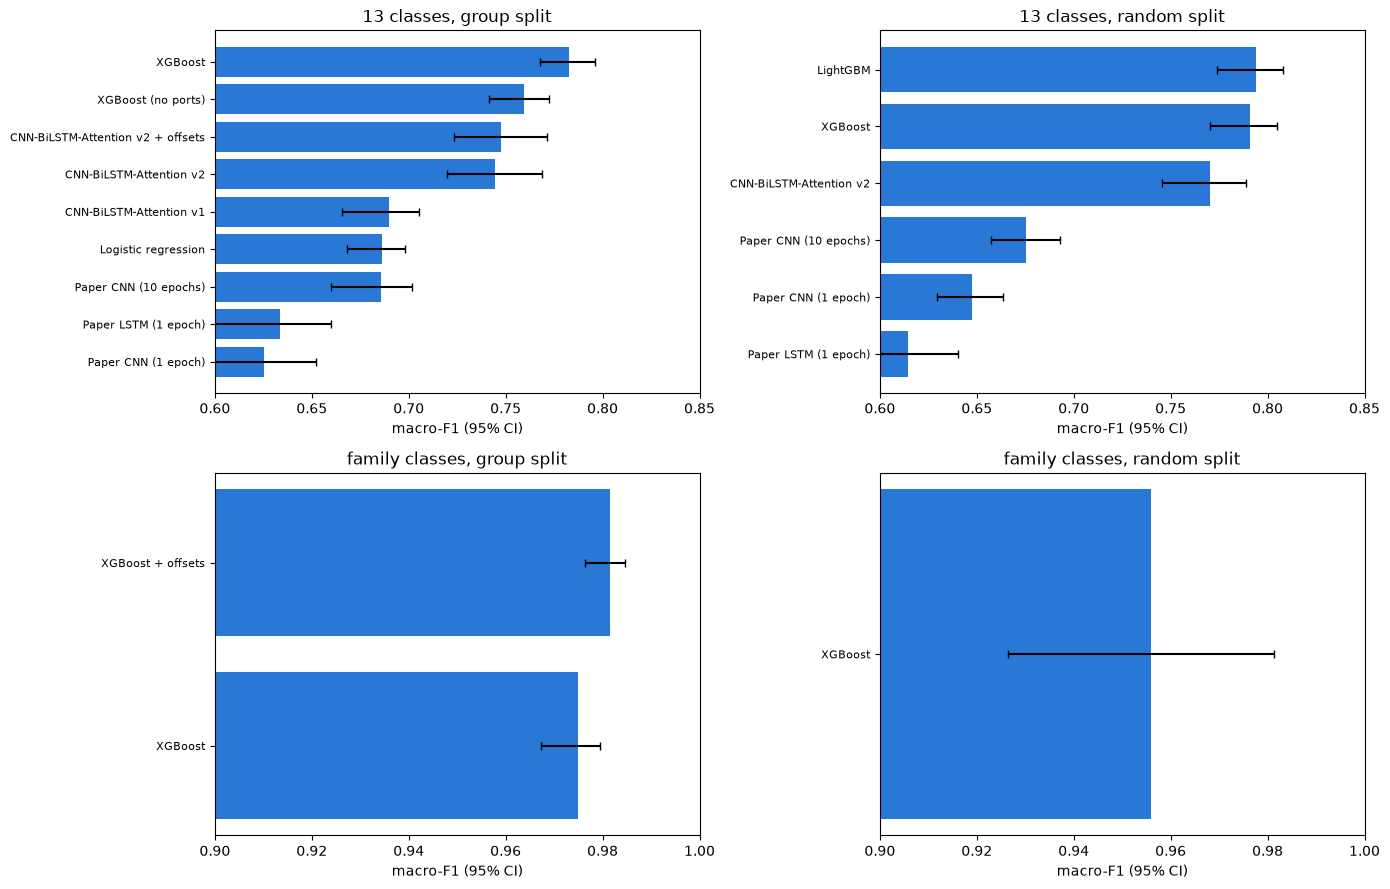

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=False)
for ax, (task, split) in zip(axes.ravel(), [("13", "group"), ("13", "random"), ("family", "group"), ("family", "random")]):
    part = metrics[(metrics.task == task) & (metrics.split == split)].sort_values("macro_f1")
    y = np.arange(len(part))
    ax.barh(y, part["macro_f1"], xerr=[part["macro_f1"] - part["macro_f1_lo"], part["macro_f1_hi"] - part["macro_f1"]], color="#2a78d6", capsize=3)
    ax.set_yticks(y); ax.set_yticklabels(part["model"], fontsize=8); ax.set_xlim(0.6 if task == "13" else 0.9, 1.0 if task == "family" else 0.85)
    ax.set_title(f"{task} classes, {split} split"); ax.set_xlabel("macro-F1 (95% CI)")
fig.tight_layout(); fig.savefig(FIGS / "performance_macro_f1_ci.png", dpi=150); plt.show()

## Attack vs. benign
Detection rate, false positive rate and ranking quality (AUC) when every attack class is treated as one.

In [5]:
binary = metrics[["task", "split", "model", "attack_detection_rate", "attack_precision", "attack_f1", "false_positive_rate", "false_negative_rate", "roc_auc_attack", "pr_auc_attack"]]
binary.to_csv(REPORTS / "performance_binary.csv", index=False)
binary.round(5)

,task,split,model,attack_detection_rate,attack_precision,attack_f1,false_positive_rate,false_negative_rate,roc_auc_attack,pr_auc_attack
0,13,group,CNN-BiLSTM-Attention v1,0.99893,0.99999,0.99946,0.00037,0.00107,0.99998,1.00000
1,13,group,CNN-BiLSTM-Attention v2,0.99990,1.00000,0.99995,0.00005,0.00010,0.99997,1.00000
2,13,group,CNN-BiLSTM-Attention v2 + offsets,0.99989,1.00000,0.99994,0.00005,0.00011,0.99998,1.00000
3,13,group,Logistic regression,0.99816,0.99977,0.99896,0.00672,0.00184,0.99958,0.99998
4,13,group,Paper CNN (10 epochs),0.99950,0.99997,0.99973,0.00101,0.00050,0.99990,0.99999
5,13,group,Paper CNN (1 epoch),0.99872,0.99989,0.99930,0.00334,0.00128,0.99967,0.99998
6,13,group,Paper LSTM (1 epoch),0.99821,0.99991,0.99906,0.00274,0.00179,0.99974,0.99999
7,13,group,XGBoost,0.99998,1.00000,0.99999,0.00000,0.00002,1.00000,1.00000
8,13,group,XGBoost (no ports),0.99977,0.99999,0.99988,0.00032,0.00023,0.99999,1.00000
9,13,random,CNN-BiLSTM-Attention v2,0.99997,0.99999,0.99998,0.00023,0.00003,1.00000,1.00000


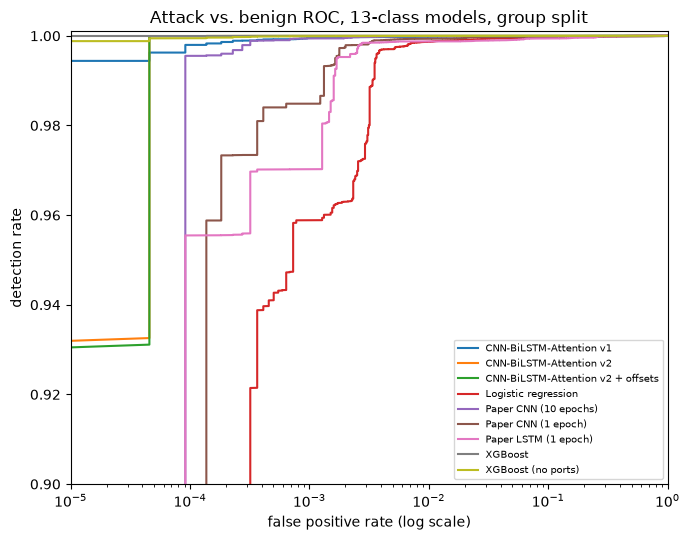

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for (task, split, slug), (fpr, tpr) in curves.items():
    if task == "13" and split == "group":
        ax.plot(fpr, tpr, label=slug)
ax.set_xscale("log"); ax.set_xlim(1e-5, 1); ax.set_ylim(0.9, 1.001)
ax.set_xlabel("false positive rate (log scale)"); ax.set_ylabel("detection rate"); ax.set_title("Attack vs. benign ROC, 13-class models, group split")
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(FIGS / "performance_roc_attack_vs_benign.png", dpi=150); plt.show()

## Is the difference between two models real?
Paired bootstrap of the macro-F1 difference (same resampled groups for both models). If the interval excludes zero, the gap is not noise.

In [7]:
def paired(task, split, a, b):
    d = boot[(task, split, a)]["macro_f1"] - boot[(task, split, b)]["macro_f1"]
    lo, hi = interval(d); return {"task": task, "split": split, "A": a, "B": b, "A - B": d.mean(), "lo": lo, "hi": hi, "A better": bool(lo > 0), "B better": bool(hi < 0)}
slugs = lambda task, split: sorted(k[2] for k in boot if k[0] == task and k[1] == split)
pairs = []
for task, split in [("13", "group"), ("13", "random"), ("family", "group"), ("family", "random")]:
    names = slugs(task, split)
    pairs += [paired(task, split, a, b) for i, a in enumerate(names) for b in names[i + 1:]]
comparison = pd.DataFrame(pairs); comparison.to_csv(REPORTS / "performance_paired_differences.csv", index=False)
comparison.round(4)

,task,split,A,B,A - B,lo,hi,A better,B better
0,13,group,CNN-BiLSTM-Attention v1,CNN-BiLSTM-Attention v2,-0.0582,-0.0858,-0.0310,False,True
1,13,group,CNN-BiLSTM-Attention v1,CNN-BiLSTM-Attention v2 + offsets,-0.0617,-0.0863,-0.0371,False,True
2,13,group,CNN-BiLSTM-Attention v1,Logistic regression,0.0033,-0.0135,0.0186,False,False
3,13,group,CNN-BiLSTM-Attention v1,Paper CNN (1 epoch),0.0619,0.0343,0.0933,True,False
4,13,group,CNN-BiLSTM-Attention v1,Paper CNN (10 epochs),0.0050,-0.0001,0.0112,False,False
5,13,group,CNN-BiLSTM-Attention v1,Paper LSTM (1 epoch),0.0561,0.0340,0.0848,True,False
6,13,group,CNN-BiLSTM-Attention v1,XGBoost,-0.0957,-0.1194,-0.0718,False,True
7,13,group,CNN-BiLSTM-Attention v1,XGBoost (no ports),-0.0707,-0.0925,-0.0499,False,True
8,13,group,CNN-BiLSTM-Attention v2,CNN-BiLSTM-Attention v2 + offsets,-0.0035,-0.0170,0.0045,False,False
9,13,group,CNN-BiLSTM-Attention v2,Logistic regression,0.0615,0.0363,0.0876,True,False


## Per-class results
Precision, recall and F1 per class for each model on the group split (13 classes).

In [8]:
pc = pd.read_csv(REPORTS / "performance_per_class.csv")
pc[(pc.task == "13") & (pc.split == "group")].pivot(index="class", columns="model", values="f1").round(3)

model,CNN-BiLSTM-Attention v1,CNN-BiLSTM-Attention v2,CNN-BiLSTM-Attention v2 + offsets,Logistic regression,Paper CNN (1 epoch),Paper CNN (10 epochs),Paper LSTM (1 epoch),XGBoost,XGBoost (no ports)
class,,,,,,,,,
BENIGN,0.984,0.999,0.998,0.970,0.980,0.992,0.973,1.000,0.997
DNS,0.574,0.622,0.674,0.446,0.561,0.579,0.569,0.687,0.602
LDAP,0.252,0.517,0.511,0.436,0.171,0.171,0.171,0.559,0.435
MSSQL,0.952,0.875,0.875,0.832,0.910,0.947,0.861,0.978,0.918
NTP,0.982,0.989,0.989,0.972,0.978,0.979,0.982,0.996,0.995
NetBIOS,0.579,0.780,0.785,0.611,0.778,0.591,0.570,0.775,0.726
Portmap,0.320,0.327,0.293,0.369,0.029,0.324,0.308,0.415,0.491
SNMP,0.717,0.647,0.672,0.653,0.720,0.718,0.727,0.756,0.713
SSDP,0.352,0.631,0.614,0.390,0.305,0.356,0.278,0.604,0.600
